In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import pandas as pd
from scipy.optimize import curve_fit

## Parte inicial

In [ ]:
# Función donde se calcula la posición y velocidad en un instante de tiempo
@njit(parallel=True)
def step(pos, vel, f, ruido, K, L, R, dt, cell_size, ncell, head, nextp):

    N = pos.shape[0]

        # Calcular fuerzas solamente si K != 0
    if K == 0:
        f[:] = 0.0

    else:
        # Reiniciar celdas
        head[:] = -1

        # Construir lista de celdas
        for i in range(N):
            cx = int(pos[i, 0] / cell_size)
            cy = int(pos[i, 1] / cell_size)

            if cx >= ncell:
                cx = ncell - 1
            if cy >= ncell:
                cy = ncell - 1

            cell_id = cx + cy * ncell
            nextp[i] = head[cell_id]
            head[cell_id] = i

        # Buscar vecinos y calcular fuerzas
        for i in prange(N):

            pix = pos[i, 0]
            piy = pos[i, 1]

            cx = int(pix / cell_size)
            cy = int(piy / cell_size)

            if cx >= ncell:
                cx = ncell - 1
            if cy >= ncell:
                cy = ncell - 1

            fix = 0.0
            fiy = 0.0

            for dx in (-1, 0, 1):
                for dy in (-1, 0, 1):

                    nx = cx + dx
                    ny = cy + dy

                    if nx < 0:
                        nx += ncell
                    elif nx >= ncell:
                        nx -= ncell

                    if ny < 0:
                        ny += ncell
                    elif ny >= ncell:
                        ny -= ncell

                    cell_id = nx + ny * ncell
                    j = head[cell_id]

                    while j != -1:

                        dxij = pos[j, 0] - pix
                        dyij = pos[j, 1] - piy

                        # Convención de imagen mínima
                        if dxij > 0.5 * L:
                            dxij -= L
                        elif dxij < -0.5 * L:
                            dxij += L

                        if dyij > 0.5 * L:
                            dyij -= L
                        elif dyij < -0.5 * L:
                            dyij += L

                        dist2 = dxij * dxij + dyij * dyij

                        # Fuerza inversa al cuadrado regularizada
                        if 0.1 < dist2 < R * R:

                            a = 0.2
                            r2_soft = dist2 + a * a

                            mag = K / (r2_soft * np.sqrt(r2_soft))

                            # Corte suave
                            cutoff = (1.0 - dist2 / (R * R)) ** 2
                            mag *= cutoff

                            fix += dxij * mag
                            fiy += dyij * mag

                        # Avanzar al siguiente vecino
                        j = nextp[j]

            f[i, 0] = fix
            f[i, 1] = fiy


    # Actualización fuerza, velocidad, posición
    for i in prange(N):
        vix = vel[i,0]
        viy = vel[i,1]

        fix = f[i,0]
        fiy = f[i,1]

        rx = ruido[i,0]
        ry = ruido[i,1]

        # Calcular velocidad
        vel[i,0] = vix + (fix - vix) * dt + rx
        vel[i,1] = viy + (fiy - viy) * dt + ry


        # Actualizar posiciones
        pos[i,0] += vel[i,0] * dt
        pos[i,1] += vel[i,1] * dt


        # Condiciones periódicas
        if pos[i,0] >= L:
            pos[i,0] -= L
        elif pos[i,0] < 0:
            pos[i,0] += L

        if pos[i,1] >= L:
            pos[i,1] -= L
        elif pos[i,1] < 0:
            pos[i,1] += L


    energia = 0.0
    for i in range(N):
        energia += 0.5 * (
            vel[i, 0]**2 + vel[i, 1]**2
        )

    energia /= N

    return (energia)

In [ ]:
# Función donde se calcula la posición y la velocidad para todos los tiempos
def sim(N,L, K, R, dt, t_relax, t_avg):

  # Inicializar parámetros celdas
  cell_size = R
  ncell = int(L / cell_size)
  head = np.empty(ncell*ncell, dtype=np.int64)
  nextp = np.empty(N, dtype=np.int64)

  # Incializar arrays parámetros fuerza, posición, velocidad
  np.random.seed(1)
  pos = np.random.uniform(0, L, (N,2))
  vel = np.zeros((N,2))
  t_total = t_relax + t_avg
  E = np.zeros(t_total)
  f=np.zeros((N,2))
  sqrtdt = np.sqrt(dt)

  # Correr step para todos los tiempos
  for t in range(t_total):
      ruido = np.random.normal(0,1, (N,2)) * sqrtdt
      E[t] = step(pos, vel, f, ruido, K, L, R, dt,cell_size, ncell, head, nextp)

  return E

## Simulación sin interacción entre partículas (k = 0)

In [ ]:
# Parámetros físicos
L = 20.0
rho = 1.0
N = int(rho * L**2)

R = 1.0
K = 0.0

# Discretización temporal
dt = 0.001

# Tiempos físicos
T_relax = 10.0
T_avg = 20.0

# Número de pasos (calculado automáticamente)
t_relax = int(round(T_relax / dt))
t_avg = int(round(T_avg / dt))
t_total = t_relax + t_avg

print("Número de partículas:", N)
print("Paso temporal:", dt)
print("Tiempo de relajación:", t_relax * dt)
print("Tiempo de medición:", t_avg * dt)
print("Tiempo total:", t_total * dt)
print("Pasos totales:", t_total)

Número de partículas: 400
Paso temporal: 0.001
Tiempo de relajación: 10.0
Tiempo de medición: 20.0
Tiempo total: 30.0
Pasos totales: 30000


In [ ]:
# Correr simulación
E = sim(N, L, K, R, dt, t_relax, t_avg)

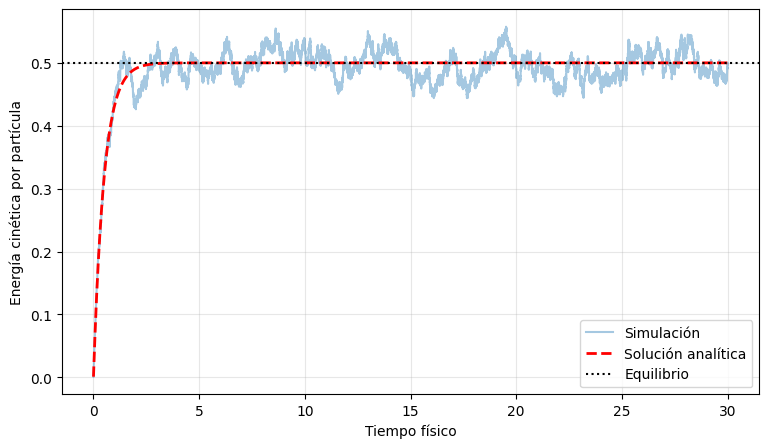

In [ ]:
# Tiempo físico
time_axis = (np.arange(len(E)) + 1) * dt

# Solución analítica para K = 0
E_teorica = 0.5 * (1 - np.exp(-2 * time_axis))

# Comparación
plt.figure(figsize=(9, 5))

plt.plot(
    time_axis, E,
    alpha=0.4,
    label="Simulación"
)

plt.plot(
    time_axis, E_teorica,
    "r--",
    linewidth=2,
    label="Solución analítica"
)

plt.axhline(
    0.5,
    color="black",
    linestyle=":",
    label="Equilibrio"
)

plt.xlabel("Tiempo físico")
plt.ylabel("Energía cinética por partícula")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ==========================================
# INCERTIDUMBRE ESTADÍSTICA POR BLOQUES
# ==========================================

def estadistica_bloques(datos, dt, duracion_bloque=2.0):

    # Número de datos por bloque
    block_size = int(round(duracion_bloque / dt))

    # Número de bloques completos
    n_blocks = len(datos) // block_size

    if n_blocks < 2:
        raise ValueError("Se necesitan al menos dos bloques.")

    # Descartar datos sobrantes
    datos = datos[:n_blocks * block_size]

    # Promedio de cada bloque
    bloques = datos.reshape(n_blocks, block_size).mean(axis=1)

    # Promedio global
    promedio = np.mean(bloques)

    # Error estándar del promedio
    error = np.std(bloques, ddof=1) / np.sqrt(n_blocks)

    return promedio, error, n_blocks


# Datos posteriores a la relajación
E_estacionaria = E[t_relax:]

# Energía cinética
E_eq, E_error, n_blocks = estadistica_bloques(
    E_estacionaria, dt
)



print("ENERGÍA CINÉTICA")
print("Promedio:", E_eq)
print("Incertidumbre:", E_error)
print("Predicción teórica:", 0.5)

print("\nNúmero de bloques:", n_blocks)

ENERGÍA CINÉTICA
Promedio: 0.4945140676140484
Incertidumbre: 0.0036631611714708105
Predicción teórica: 0.5

Número de bloques: 10


In [ ]:
# VALORES TEÓRICOS
# Tiempo característico de relajación de la energía
tau_E = 0.5

# Tiempo para alcanzar el 99 % del equilibrio teórico
t_eq = -0.5 * np.log(0.01)

print("Tiempo característico de relajación:", tau_E)
print("Tiempo de equilibración teórico (1 %):", t_eq)

Tiempo característico de relajación: 0.5
Tiempo de equilibración teórico (1 %): 2.3025850929940455


Tiempo de relajación simulado: 0.43944093938415374
Incertidumbre aproximada del ajuste: 0.023653070378465077
Tiempo de relajación teórico: 0.5


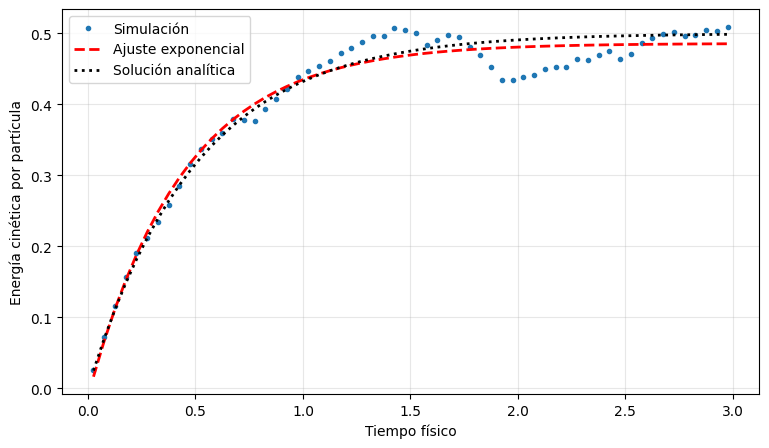

In [ ]:
# ==========================================
# ESTIMACIÓN NUMÉRICA DEL TIEMPO DE RELAJACIÓN
# ==========================================

# Modelo exponencial de relajación
def modelo_relajacion(t, E_inf, C, tau):
    return E_inf - C * np.exp(-t / tau)


# Seleccionar el intervalo transitorio
mask = time_axis <= 3.0

t_fit = time_axis[mask]
E_fit = E[mask]

# Promediar en ventanas para reducir fluctuaciones
window = max(1, int(round(0.05 / dt)))

n = len(E_fit) // window

t_fit = t_fit[:n * window].reshape(n, window).mean(axis=1)
E_fit = E_fit[:n * window].reshape(n, window).mean(axis=1)

# Ajuste exponencial
parametros, covarianza = curve_fit(
    modelo_relajacion,
    t_fit,
    E_fit,
    p0=[0.5, 0.5, 0.5],
    bounds=([0, 0, 0.01], [np.inf, np.inf, 10.0])
)

E_inf_fit, C_fit, tau_fit = parametros

# Incertidumbre aproximada del ajuste
tau_error = np.sqrt(covarianza[2, 2])

# Predicción teórica
tau_teorico = 0.5

print("Tiempo de relajación simulado:", tau_fit)
print("Incertidumbre aproximada del ajuste:", tau_error)
print("Tiempo de relajación teórico:", tau_teorico)


# ==========================================
# GRÁFICA DEL AJUSTE
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    t_fit,
    E_fit,
    "o",
    markersize=3,
    label="Simulación"
)

plt.plot(
    t_fit,
    modelo_relajacion(t_fit, *parametros),
    "r--",
    linewidth=2,
    label="Ajuste exponencial"
)

plt.plot(
    t_fit,
    0.5 * (1 - np.exp(-2 * t_fit)),
    "k:",
    linewidth=2,
    label="Solución analítica"
)

plt.xlabel("Tiempo físico")
plt.ylabel("Energía cinética por partícula")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Simulación con interacción entre partículas (k > 0)

In [ ]:
# Parámetros físicos
L = 20.0
rho = 1.0
N = int(rho * L**2)

R = 1.0
K = 2

# Discretización temporal
dt = 0.001

# Tiempos físicos
T_relax = 10.0
T_avg = 20.0

# Número de pasos (calculado automáticamente)
t_relax = int(round(T_relax / dt))
t_avg = int(round(T_avg / dt))
t_total = t_relax + t_avg

print("Número de partículas:", N)
print("Paso temporal:", dt)
print("Tiempo de relajación:", t_relax * dt)
print("Tiempo de medición:", t_avg * dt)
print("Tiempo total:", t_total * dt)
print("Pasos totales:", t_total)

Número de partículas: 400
Paso temporal: 0.001
Tiempo de relajación: 10.0
Tiempo de medición: 20.0
Tiempo total: 30.0
Pasos totales: 30000


In [ ]:
# Correr simulación
E = sim(N, L, K, R, dt, t_relax, t_avg)

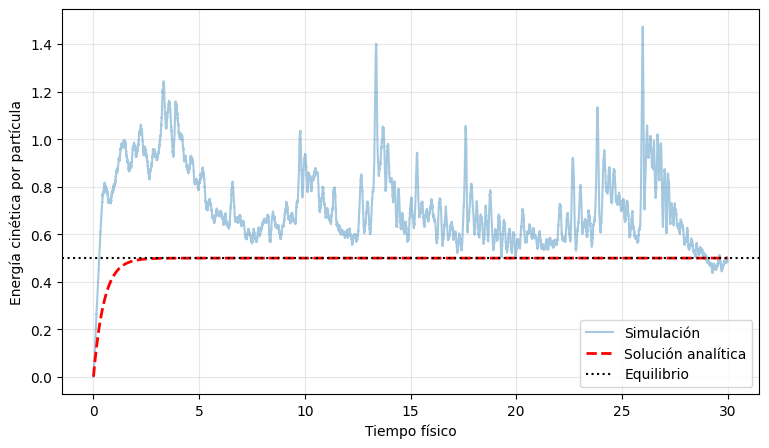

In [ ]:
# Tiempo físico
time_axis = (np.arange(len(E)) + 1) * dt

# Solución analítica para K = 0
E_teorica = 0.5 * (1 - np.exp(-2 * time_axis))

# Comparación
plt.figure(figsize=(9, 5))

plt.plot(
    time_axis, E,
    alpha=0.4,
    label="Simulación"
)

plt.plot(
    time_axis, E_teorica,
    "r--",
    linewidth=2,
    label="Solución analítica"
)

plt.axhline(
    0.5,
    color="black",
    linestyle=":",
    label="Equilibrio"
)

plt.xlabel("Tiempo físico")
plt.ylabel("Energía cinética por partícula")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ==========================================
# INCERTIDUMBRE ESTADÍSTICA POR BLOQUES
# ==========================================

def estadistica_bloques(datos, dt, duracion_bloque=2.0):

    # Número de datos por bloque
    block_size = int(round(duracion_bloque / dt))

    # Número de bloques completos
    n_blocks = len(datos) // block_size

    if n_blocks < 2:
        raise ValueError("Se necesitan al menos dos bloques.")

    # Descartar datos sobrantes
    datos = datos[:n_blocks * block_size]

    # Promedio de cada bloque
    bloques = datos.reshape(n_blocks, block_size).mean(axis=1)

    # Promedio global
    promedio = np.mean(bloques)

    # Error estándar del promedio
    error = np.std(bloques, ddof=1) / np.sqrt(n_blocks)

    return promedio, error, n_blocks


# Datos posteriores a la relajación
E_estacionaria = E[t_relax:]

# Energía cinética
E_eq, E_error, n_blocks = estadistica_bloques(
    E_estacionaria, dt
)


print("ENERGÍA CINÉTICA")
print("Promedio:", E_eq)
print("Incertidumbre:", E_error)
print("Predicción teórica:", 0.5)

print("\nNúmero de bloques:", n_blocks)

ENERGÍA CINÉTICA
Promedio: 0.6797662803350304
Incertidumbre: 0.028548270530047402
Predicción teórica: 0.5

Número de bloques: 10


Tiempo de relajación simulado: 0.34250028014680667
Incertidumbre aproximada del ajuste: 0.025345678662923497
Tiempo de relajación teórico: 0.5


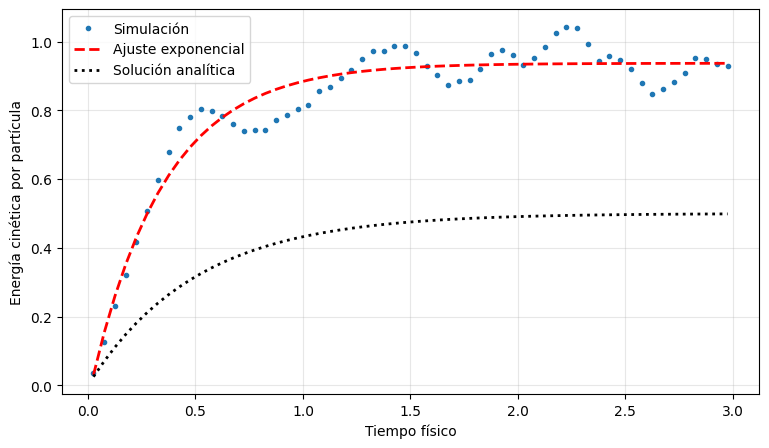

In [ ]:
# ==========================================
# ESTIMACIÓN NUMÉRICA DEL TIEMPO DE RELAJACIÓN
# ==========================================

# Modelo exponencial de relajación
def modelo_relajacion(t, E_inf, C, tau):
    return E_inf - C * np.exp(-t / tau)


# Seleccionar el intervalo transitorio
mask = time_axis <= 3.0

t_fit = time_axis[mask]
E_fit = E[mask]

# Promediar en ventanas para reducir fluctuaciones
window = max(1, int(round(0.05 / dt)))

n = len(E_fit) // window

t_fit = t_fit[:n * window].reshape(n, window).mean(axis=1)
E_fit = E_fit[:n * window].reshape(n, window).mean(axis=1)

# Ajuste exponencial
parametros, covarianza = curve_fit(
    modelo_relajacion,
    t_fit,
    E_fit,
    p0=[0.5, 0.5, 0.5],
    bounds=([0, 0, 0.01], [np.inf, np.inf, 10.0])
)

E_inf_fit, C_fit, tau_fit = parametros

# Incertidumbre aproximada del ajuste
tau_error = np.sqrt(covarianza[2, 2])

# Predicción teórica
tau_teorico = 0.5

print("Tiempo de relajación simulado:", tau_fit)
print("Incertidumbre aproximada del ajuste:", tau_error)
print("Tiempo de relajación teórico:", tau_teorico)


# ==========================================
# GRÁFICA DEL AJUSTE
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    t_fit,
    E_fit,
    "o",
    markersize=3,
    label="Simulación"
)

plt.plot(
    t_fit,
    modelo_relajacion(t_fit, *parametros),
    "r--",
    linewidth=2,
    label="Ajuste exponencial"
)

plt.plot(
    t_fit,
    0.5 * (1 - np.exp(-2 * t_fit)),
    "k:",
    linewidth=2,
    label="Solución analítica"
)

plt.xlabel("Tiempo físico")
plt.ylabel("Energía cinética por partícula")
plt.legend()
plt.grid(alpha=0.3)
plt.show()